In [1]:
from sklearn.model_selection import train_test_split
import pandas as pd


student_df = pd.read_csv('../data/raw/student_mental_health.csv')

X = student_df.drop(columns=["Student_ID", "Mental_Health_Risk", "Risk_Encoded"], errors='ignore')
y = student_df['Mental_Health_Risk']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Shape X_train :", X_train.shape)
print("Shape X_test  :", X_test.shape)

Shape X_train : (1600, 15)
Shape X_test  : (400, 15)


In [2]:
ordinal_cols = ["Physical_Activity", "Diet_Quality"]
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.drop(ordinal_cols).tolist()

print(f"Variables numériques ({len(num_cols)}) :", num_cols)
print(f"Variables catégorielles ({len(cat_cols)}) :", cat_cols)


Variables numériques (10) : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Variables catégorielles (3) : ['Gender', 'Part_Time_Job', 'Previous_Mental_Health_History']


In [3]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder,LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer



num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
            categories=[
                ['Low', 'Moderate', 'High'],
                ["Poor", "Average", "Good"]
            ],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])


label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)



preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('ordinal', ordinal_pipeline, ordinal_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train_encoded)
    trained_models[name] = model

In [5]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score
)

predictions = {}
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, y_pred),
        "Precision": precision_score(y_test_encoded, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_encoded, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test_encoded, y_pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.76,0.7596,0.76,0.7598
1,Random Forest,0.70,0.6998,0.70,0.6998
2,Decision Tree,0.58,0.5813,0.58,0.5806



=== Logistic Regression ===
              precision    recall  f1-score   support

        High       0.81      0.82      0.82       136
         Low       0.82      0.82      0.82       132
      Medium       0.64      0.64      0.64       132

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400


=== Decision Tree ===
              precision    recall  f1-score   support

        High       0.61      0.61      0.61       136
         Low       0.66      0.65      0.66       132
      Medium       0.47      0.48      0.47       132

    accuracy                           0.58       400
   macro avg       0.58      0.58      0.58       400
weighted avg       0.58      0.58      0.58       400


=== Random Forest ===
              precision    recall  f1-score   support

        High       0.75      0.77      0.76       136
         Low       0.79      0.77      0.78       132


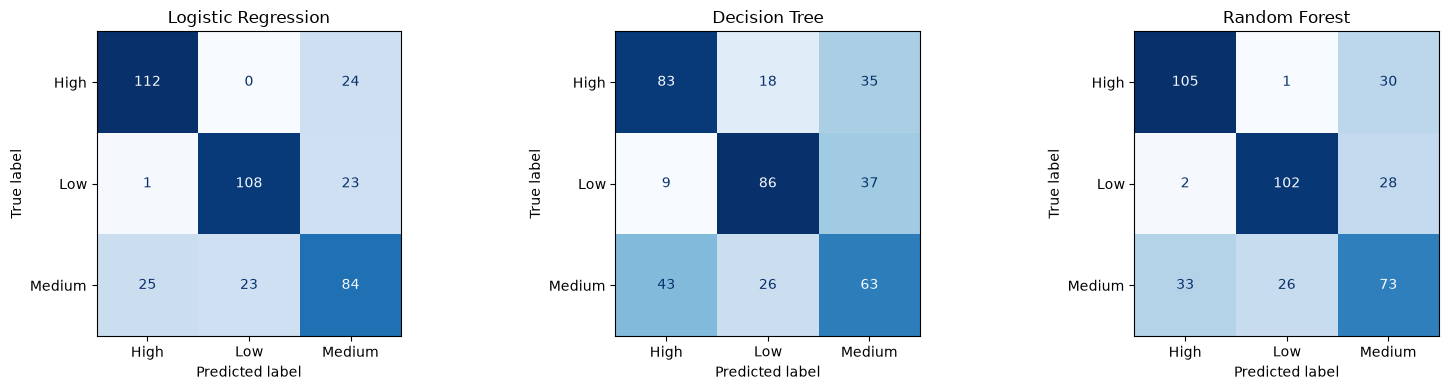

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

target_names = label_encoder.classes_

for name in trained_models:
    print(f"\n=== {name} ===")
    print(classification_report(y_test_encoded, predictions[name], target_names=target_names, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test_processed, y_test_encoded,
        display_labels=target_names, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

promising_models = {
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

param_grids = {
    "Random Forest": {
        "model__n_estimators": [150, 250],
        "model__max_depth": [10, 15, 20],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
        "model__class_weight": ["balanced", "balanced_subsample"]
    },
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1.0, 10.0],
        "model__solver": ["lbfgs", "saga"],
        "model__class_weight": ["balanced"]
    }
}

optimized_models = {}
tuning_results = []

for name, model in promising_models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    grid = GridSearchCV(
        pipe,
        param_grids[name],
        cv=5,
        scoring="f1_weighted",
        n_jobs=-1
    )
    grid.fit(X_train, y_train_encoded)
    optimized_models[name] = grid.best_estimator_
    tuning_results.append({
        "Model": name,
        "Best CV F1-Score": grid.best_score_,
        "Best Params": grid.best_params_
    })

tuning_df = pd.DataFrame(tuning_results).sort_values("Best CV F1-Score", ascending=False).reset_index(drop=True)
display(tuning_df)

In [ ]:
final_results = []

for name, model in optimized_models.items():
    y_pred_opt = model.predict(X_test)
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, y_pred_opt),
        "Precision": precision_score(y_test_encoded, y_pred_opt, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_encoded, y_pred_opt, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test_encoded, y_pred_opt, average="weighted", zero_division=0)
    })

comparison_df = pd.DataFrame(final_results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

best_model_name = comparison_df.iloc[0]["Model"]
best_model = optimized_models[best_model_name]

print("Meilleur modèle :", best_model_name)

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_best = best_model.predict(X_test)
target_names = label_encoder.classes_

print(classification_report(y_test_encoded, y_pred_best, target_names=target_names, zero_division=0))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test_encoded,
    display_labels=target_names, cmap="Blues"
)
plt.title(f"Matrice de confusion - {best_model_name}")
plt.show()

In [ ]:
errors = X_test.copy()
errors["Actual"] = label_encoder.inverse_transform(y_test_encoded)
errors["Predicted"] = label_encoder.inverse_transform(y_pred_best)

errors = errors[errors["Actual"] != errors["Predicted"]]

print("Nombre d'erreurs :", len(errors), "sur", len(X_test))
display(errors[["Actual", "Predicted"]].value_counts())
display(errors.head(5))

In [ ]:
import os, json, joblib
from sklearn.metrics import confusion_matrix

os.makedirs("../models", exist_ok=True)
joblib.dump(best_model, "../models/mental_health_pipeline.joblib")
joblib.dump(label_encoder, "../models/label_encoder.joblib")

row = comparison_df.iloc[0]

metrics = {
    "model_name": best_model_name,
    "accuracy": round(float(row["Accuracy"]), 4),
    "precision": round(float(row["Precision"]), 4),
    "recall": round(float(row["Recall"]), 4),
    "f1_score": round(float(row["F1-Score"]), 4),
    "classes": label_encoder.classes_.tolist(),
    "confusion_matrix": confusion_matrix(y_test_encoded, y_pred_best).tolist(),
}

with open("../models/evaluation_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Sauvegarde réussie !")